# Garment Worker Productivity - Model Comparison

This notebook compares different regression models for predicting garment team productivity.

The same data preparation, chronological train/test split and evaluation metrics from the previous milestone are kept so that the models can be compared fairly.

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

## 1. Loading and Preparing the Data

In this part the dataset is loaded and prepared using the same cleaning and chronological train/test split used in the previous notebook-02. Keeping the same split means that each model is evaluated on the same unseen test data.

In [4]:
# Loads the dataset
df = pd.read_csv("../data/garments_worker_productivity.csv")

df["department"] = df["department"].str.strip()  # Cleans the department labels
df["date"] = pd.to_datetime(df["date"])  # Converst the date column

df = df.sort_values("date").reset_index(drop=True)  # Sorts the data by date

df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,11,0.70,4.15,NaN,1440,0,0.0,0,0,12.0,0.436326
2,2015-01-01,Quarter1,sweing,Thursday,4,0.65,23.69,861.0,7200,0,0.0,0,0,60.0,0.521180
3,2015-01-01,Quarter1,finishing,Thursday,7,0.80,2.90,NaN,960,0,0.0,0,0,8.0,0.540729
4,2015-01-01,Quarter1,finishing,Thursday,4,0.75,3.94,NaN,2160,0,0.0,0,0,18.0,0.593056


### 1.1 Features, Target and Train/Test Split

In [5]:
# Separates the model inputs from the target
X = df.drop(columns=["actual_productivity", "date"])
y = df["actual_productivity"]

# Finds the unique dates in chronological order
unique_dates = df["date"].sort_values().unique()

# It uses approximately the first 80% of dates for training
split_index = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_index]

# Creating the training and test sets using whole dates
train_mask = df["date"] < cutoff_date
test_mask = df["date"] >= cutoff_date

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]
y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((943, 13), (254, 13), (943,), (254,))

## 2. Preprocessing

The same preprocessing approach from the previous notebook-02 is used so that the learned models are trained on consistently prepared data.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [7]:
# Categorical features
categorical_features = [
    "quarter",
    "department",
    "day",
    "team"
]

# Numerical features
numerical_features = [
    "targeted_productivity",
    "smv",
    "over_time",
    "incentive",
    "idle_time",
    "idle_men",
    "no_of_style_change",
    "no_of_workers"
]

# WIP
wip_feature = ["wip"]

In [8]:
# Prepares the numerical features
numerical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepares WIP separately
wip_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler())
])

# Converts categorical values into numerical columns
categorical_preprocessor = OneHotEncoder(
    handle_unknown="ignore"
)

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_preprocessor, numerical_features),
        ("wip", wip_preprocessor, wip_feature),
        ("cat", categorical_preprocessor, categorical_features)
    ]
)

### Baseline Model

In [32]:
# Creates the same mean baseline used in the previous notebook
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = root_mean_squared_error(y_test, y_pred_baseline)
baseline_r2 = r2_score(y_test, y_pred_baseline)

## 3. Linear Regression

In my project, Linear Regression is used as the first learned model. Unlike the DummyRegressor, it uses the input features to learn relationships with `actual_productivity`.

The preprocessing pipeline is combined with the model so that the same preparation is applied to the training and test data.

In [10]:
# Combining preprocessing with Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [11]:
# Training the Linear Regression model
linear_model.fit(X_train, y_train);

In [12]:
# Predicts productivity for the unseen test data
y_pred_linear = linear_model.predict(X_test)

In [ ]:
# Evaluates the Linear Regression predictions
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = root_mean_squared_error(y_test, y_pred_linear)
linear_r2 = r2_score(y_test, y_pred_linear)

print(f"Linear Regression MAE: {linear_mae:.4f}")
print(f"Linear Regression RMSE: {linear_rmse:.4f}")
print(f"Linear Regression R²: {linear_r2:.4f}")

Linear Regression MAE: 0.2853
Linear Regression RMSE: 1.1537
Linear Regression R²: -49.8455


In [14]:
# Check the range of Linear Regression predictions
print("Lowest prediction:", y_pred_linear.min())
print("Highest prediction:", y_pred_linear.max())

Lowest prediction: 0.35134152186993434
Highest prediction: 12.673362930069903


In [15]:
# Compare incentive values in the training and test sets
print("Highest training incentive:", X_train["incentive"].max())
print("Highest test incentive:", X_test["incentive"].max())

Highest training incentive: 138
Highest test incentive: 3600


### Linear Regression Observations

As we can see the Linear Regression performed much worse than the baseline. Further checks showed that the test data contains incentive values much higher than those seen during training. The highest training incentive was 138, while the test set contained values up to 3600.

The model also produced an unrealistic maximum productivity prediction of approximately 12.67. This suggests that Linear Regression struggled to generalise when the test data contained values outside the range it had learned from.

## 4. Decision Tree Regressor

Next I used a Decision Tree Regressor as the second learned model. It makes predictions by splitting the training data into groups based on the input features.

Unlike Linear Regression, it can learn non-linear relationships between the features and productivity.

In [16]:
# Combines preprocessing with the Decision Tree model
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

In [17]:
# This trains the Decision Tree model
tree_model.fit(X_train, y_train);

In [18]:
# Makespredictions on the test data
y_pred_tree = tree_model.predict(X_test)

In [19]:
# Then evaluate the Decision Tree predictions
tree_mae = mean_absolute_error(y_test, y_pred_tree)
tree_rmse = root_mean_squared_error(y_test, y_pred_tree)
tree_r2 = r2_score(y_test, y_pred_tree)

print(f"Decision Tree MAE: {tree_mae:.4f}")
print(f"Decision Tree RMSE: {tree_rmse:.4f}")
print(f"Decision Tree R²: {tree_r2:.4f}")

Decision Tree MAE: 0.1076
Decision Tree RMSE: 0.1779
Decision Tree R²: -0.2083


### Decision Tree Observation

The Decision Tree achieved a lower MAE than the baseline, meaning its predictions were closer to the real values on average. However, its RMSE and R² were worse than the baseline. This suggests that although the tree improved some predictions, its also made some large errors which increased the RMSE.

## 5. Random Forest Regressor

The last model used in my project is Random Forest which is an ensemble model made up of many decision trees. Instead of relying on one tree, it combines predictions from multiple trees, which can make the model more stable.

In [20]:
# Combines preprocessing with the Random Forest model
forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,  # use 100 trees
        random_state=42
    ))
])

In [21]:
# Theen train the Random Forest
forest_model.fit(X_train, y_train);

# Make predictions
y_pred_forest = forest_model.predict(X_test)

In [22]:
# Evaluate the predictions
forest_mae = mean_absolute_error(y_test, y_pred_forest)
forest_rmse = root_mean_squared_error(y_test, y_pred_forest)
forest_r2 = r2_score(y_test, y_pred_forest)

print(f"Random Forest MAE: {forest_mae:.4f}")
print(f"Random Forest RMSE: {forest_rmse:.4f}")
print(f"Random Forest R²: {forest_r2:.4f}")

Random Forest MAE: 0.0879
Random Forest RMSE: 0.1329
Random Forest R²: 0.3256


### Random Forest Observation

The Random Forest performed the best out of all models and baseline so far. It achieved the lowest MAE AND RMSE meaning its predictions were closer to the real producitivity values on average anf it made fewer large errors.

It also achieved a positive R² of  0.3256 showing that it explaind more of the variation in productivity than the baseline model

## 6. Model Comparison

### 6.1 Model Settings

The models were compared using default settings so that they could be evaluated fairly using the same train/test split and metrics. Linear Regression used the default scikit-learn settings. The Decision Tree Regressor used the default settings with `random_state=42`. The Random Forest used 100 trees (`n_estimators=100`) and `random_state=42`.

No additional hyperparameter tuning was carried out at this stage including the comparison of models. Further tuning could be tested later using only the training data rather than the final test set.

In [23]:
# Comparing all model results in one table
results = pd.DataFrame({
    "Model": [
        "DummyRegressor",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        0.1216,
        linear_mae,
        tree_mae,
        forest_mae
    ],
    "RMSE": [
        0.1659,
        linear_rmse,
        tree_rmse,
        forest_rmse
    ],
    "R²": [
        -0.0515,
        linear_r2,
        tree_r2,
        forest_r2
    ]
})

results

,Model,MAE,RMSE,R²
0,DummyRegressor,0.121600,0.165900,-0.051500
1,Linear Regression,0.285298,1.153731,-49.845543
2,Decision Tree,0.107581,0.177855,-0.208301
3,Random Forest,0.087892,0.132870,0.325633


### Comparison Observation

The Random Forest produced the strongest results overall. It had the lowest MAE and RMSE and was the only learned model to achieve a clearly positive R².

The Decision Tree improved the MAE compared with the baseline but had a worse RMSE and R². Linear Regression performed poorly because it produced some extreme predictions on the later test data.

## 7. Residual Analysis

Using residual analysis we can find the difference between the actual productivity value and the value predicted by the model. The residual plot below is used to check where the Random Forest makes larger prediction errors.

In [24]:
# Calculates Random Forest residuals
forest_residuals = y_test - y_pred_forest

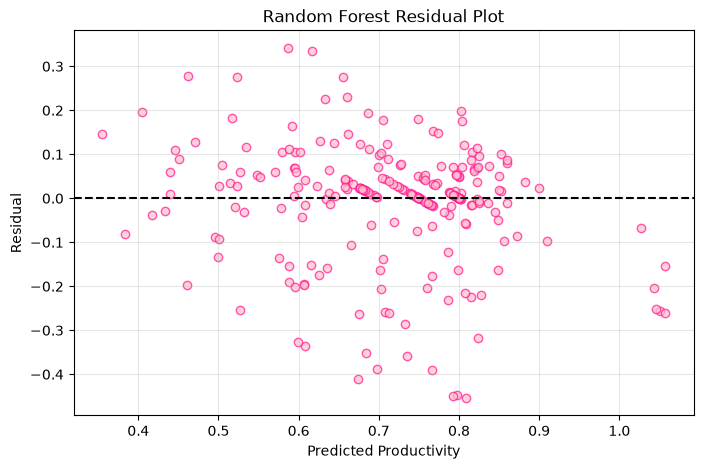

In [25]:
# Plots the Random Forest residuals
plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_forest,
    forest_residuals,
    color="pink",
    edgecolor="deeppink",
    alpha=0.7
)

plt.axhline(y=0, color="black", linestyle="--")

plt.xlabel("Predicted Productivity")
plt.ylabel("Residual")
plt.title("Random Forest Residual Plot")

plt.grid(alpha=0.3)
plt.show()

### Residual Plot Observation

The residuals are scattered around the zero line which suggests that the Random Forest model is generally making baladnced predictions rather than being consistently too high or too low. However, there are still some points further away from zero showing that the model makes larger errors for some observations. 
In general, the residual plot suggest that the model performs reasonably well although it is not perfect.

### Largest Prediction Errors

In [30]:
# A table to examine the largest Random Forest prediction errors
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_pred_forest
error_analysis["Residual"] = y_test - y_pred_forest
error_analysis["Absolute Error"] = abs(error_analysis["Residual"])

# Shows the 10 observations with the largest errors
error_analysis.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,Actual,Predicted,Residual,Absolute Error
1031,Quarter1,finishing,Tuesday,5,0.70,4.60,NaN,3360,0,0.0,0,0,8.0,0.354444,0.808330,-0.453885,0.453885
1014,Quarter1,finishing,Monday,7,0.80,4.60,NaN,3360,0,0.0,0,0,8.0,0.342361,0.792654,-0.450292,0.450292
994,Quarter1,finishing,Sunday,7,0.80,4.60,NaN,3360,0,0.0,0,0,8.0,0.350417,0.797221,-0.446805,0.446805
1129,Quarter2,finishing,Monday,8,0.65,3.90,NaN,0,960,0.0,0,0,8.0,0.264062,0.673914,-0.409851,0.409851
970,Quarter4,finishing,Saturday,8,0.75,4.60,NaN,3360,0,0.0,0,0,8.0,0.376597,0.766180,-0.389583,0.389583
1035,Quarter1,finishing,Tuesday,6,0.75,2.90,NaN,3360,0,0.0,0,0,8.0,0.309333,0.697814,-0.388481,0.388481
950,Quarter4,finishing,Thursday,8,0.75,4.60,NaN,3360,0,0.0,0,0,8.0,0.376597,0.734716,-0.358118,0.358118
1047,Quarter1,sweing,Wednesday,6,0.75,18.79,52.0,3960,0,0.0,0,0,33.0,0.332146,0.683709,-0.351562,0.351562
1023,Quarter1,finishing,Monday,2,0.70,3.90,NaN,1200,0,0.0,0,0,10.0,0.928850,0.587200,0.341650,0.341650
953,Quarter4,finishing,Thursday,6,0.75,2.90,NaN,3360,0,0.0,0,0,8.0,0.271875,0.607930,-0.336055,0.336055


### Error Analysis Observation

Looking at the ten largest prediction errors most of them came from the `finishing` department. Many of these observations also had a small number of workers, usually 8. For most of the largest errors, the Random Forest predicted productivity higher than the actual value. This suggests that the model had more difficulty predicting some low-productivity observations from the finishing department. There was also one large error from the `sweing` department, so the problem was not limited completely to finishing.

## 8. Random Forest Feature Importance

Then I thought of a question; ''Which inputs did the Random Forest rely on most when making predictions?''. So, here Feature Importance is used to see which processed input features contributed most to the Random Forest predictions.

In [26]:
feature_names = forest_model.named_steps["preprocessor"].get_feature_names_out()  # Names of the features after preprocessing

feature_importances = forest_model.named_steps["regressor"].feature_importances_  # Random Forest feature importance values

In [27]:
# Puts feature names and importance values into a table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# Sorts from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(10)

,Feature,Importance
0,num__targeted_productivity,0.226909
3,num__incentive,0.146020
1,num__smv,0.135837
2,num__over_time,0.083173
7,num__no_of_workers,0.072591
16,cat__day_Monday,0.023863
21,cat__day_Wednesday,0.019938
8,wip__wip,0.018295
12,cat__quarter_Quarter4,0.018230
18,cat__day_Sunday,0.017348


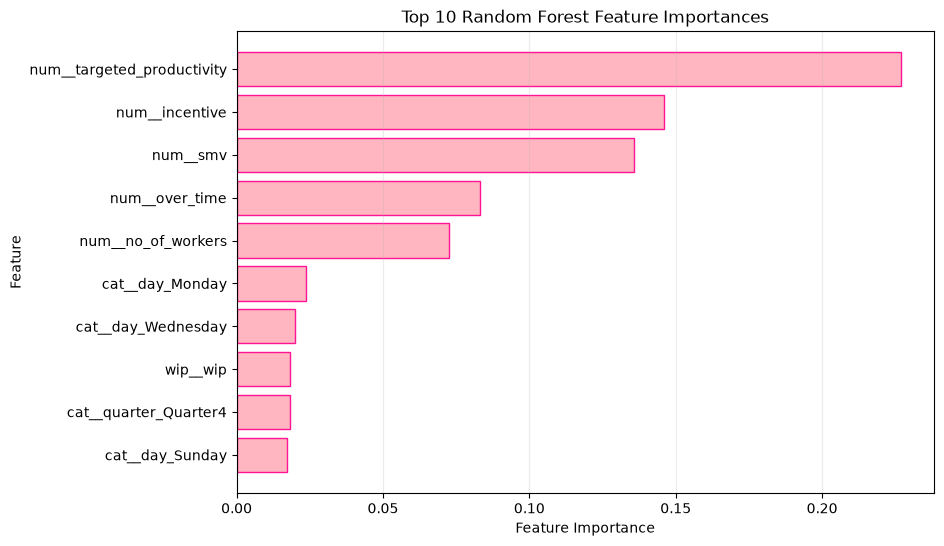

In [28]:
# Plots the 10 most important features from above table
top_features = importance_df.head(10)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1],
    color="lightpink",
    edgecolor="deeppink"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")

plt.grid(axis="x", alpha=0.25)
plt.show()

### Feature Importance Observation

The Random Forest used `targeted_productivity` as the most important feature, followed by incentive and smv. `over_time` and `no_of_workers` also had some importance, while the day and quarter categories had much smaller values.

This shows which features the Random Forest relied on more when making its splits, but it does not mean that these features directly cause productivity to change. Feature importance should also be interpreted carefully because some features can share similar information which may affect how the importance is divided between them!

## 9. Conclusion of This Notebook

The Random Forest was the best-performing model in the current comparison. It achieved the lowest MAE of 0.0879 and RMSE of 0.1329, as well as the highest R² value of 0.3256.The Decision Tree improved on the baseline for MAE but performed worse for RMSE and R². Linear Regression performed poorly and produced some unrealistic predictions when the later test data contained incentive values much higher than those seen during training.

Although Random Forest performed best, its R² score shows that there is still a large amount of variation in productivity that the model does not explain. The dataset also covers a relatively short time period, so the results may not generalise to other workplaces or time periods. For my next step in my project, the Random Forest could be tuned further using only the training data, and its prediction errors could be investigated in more detail.